<a href="https://colab.research.google.com/github/uday-andotra/WQU/blob/main/MScFE_622_SM_GWP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## MScFE 622 SM GWP1 A

<!-- merged from: MScFE 622 SM GWP1 A.ipynb (Jupy Tools) -->

# MScFE 622 Stochastic Modeling – Group Work Project #1
## Team Member A – Thao Thi Phuong Pham
**Student Group 16877** | August 2026

**Assigned responsibilities**
- Step 1(a): Heston (1993) calibration via Lewis (2001) – 15-day slice
- Step 2(b): Bates (1996) calibration via Carr–Madan (1999) – 60-day slice

*(Step 3 is performed jointly by the whole team – see `Group_Step3_Notebook.ipynb`.)*


In [ ]:
import numpy as np
from scipy.special import roots_legendre
from scipy.integrate import quad
import matplotlib.pyplot as plt
import os

os.makedirs('figures_A', exist_ok=True)
np.random.seed(42)

# Global market data
S0 = 232.90
r  = 0.015
T_15 = 15 / 250.0
T_60 = 60 / 250.0

strikes = np.array([227.5, 230.0, 232.5, 235.0, 237.5])

# 15-day market quotes
C_MKT_15 = np.array([10.52, 10.05, 7.75, 6.01, 4.75])
P_MKT_15 = np.array([4.32, 5.20, 6.45, 7.56, 8.78])

# 60-day market quotes
C_MKT_60 = np.array([16.78, 17.65, 16.86, 16.05, 15.10])
P_MKT_60 = np.array([11.03, 12.15, 13.37, 14.75, 15.62])


## Step 1(a) – Heston Lewis Calibration (15-day)

We calibrate the classic Heston model to the 15-day call and put quotes using the Lewis (2001) Fourier integral and a regular MSE objective, subject to positivity, correlation and Feller constraints.

In [ ]:
# Final reported parameters (differential-evolution + polish)
kappa_h, theta_h, sigma_h, rho_h, v0_h = (
    3.29312247, 0.27254061, 1.33975356, -0.99899872, 0.08429371
)

# Gauss-Legendre quadrature grid for the Lewis integral
N_QUAD, U_MAX = 192, 250.0
x, w = roots_legendre(N_QUAD)
u_grid  = 0.5 * (x + 1.0) * U_MAX
weights = 0.5 * U_MAX * w

def heston_cf_lewis(z, T, r, kappa, theta, sigma, rho, v0):
    i = 1j
    d = -np.sqrt((rho*sigma*z*i - kappa)**2 - sigma**2*(-z*i - z**2))
    g = (kappa - rho*sigma*z*i + d) / (kappa - rho*sigma*z*i - d)
    H1 = (r*z*i*T
          + (kappa*theta/sigma**2)
          * ((kappa - rho*sigma*z*i + d)*T
             - 2.0*np.log((1.0 - g*np.exp(d*T))/(1.0 - g))))
    H2 = (v0/sigma**2)*(kappa - rho*sigma*z*i + d)*(1.0 - np.exp(d*T))/(1.0 - g*np.exp(d*T))
    return np.exp(H1 + H2)

def heston_calls_lewis(params, K, T):
    kappa, theta, sigma, rho, v0 = params
    cf = heston_cf_lewis(u_grid - 0.5j, T, r, kappa, theta, sigma, rho, v0)
    phase = np.exp(1j * np.outer(np.log(S0/K), u_grid))
    integrand = (phase * cf / (u_grid**2 + 0.25)).real
    return S0 - np.exp(-r*T)*np.sqrt(S0*K)/np.pi * (integrand @ weights)

params_h = (kappa_h, theta_h, sigma_h, rho_h, v0_h)
model_calls_15 = heston_calls_lewis(params_h, strikes, T_15)
model_puts_15  = model_calls_15 - S0 + strikes * np.exp(-r*T_15)

call_err_15 = model_calls_15 - C_MKT_15
put_err_15  = model_puts_15  - P_MKT_15
mse_15  = np.mean(np.concatenate([call_err_15, put_err_15])**2)
rmse_15 = np.sqrt(mse_15)
feller_15 = 2*kappa_h*theta_h - sigma_h**2

print('='*60)
print('STEP 1(a) - Heston Lewis Calibration (15-day)')
print('='*60)
print(f'Parameters: kappa={kappa_h:.8f}, theta={theta_h:.8f}')
print(f'            sigma={sigma_h:.8f}, rho={rho_h:.8f}, v0={v0_h:.8f}')
print(f'MSE  = {mse_15:.8f}')
print(f'RMSE = {rmse_15:.8f}')
print(f'Feller margin = {feller_15:.3e}')
print()
print(f"{'Type':<6} {'Strike':>8} {'Market':>8} {'Model':>10} {'Error':>8}")
print('-'*44)
for K,m,mod,e in zip(strikes, C_MKT_15, model_calls_15, call_err_15):
    print(f"{'Call':<6} {K:8.1f} {m:8.2f} {mod:10.4f} {e:8.4f}")
for K,m,mod,e in zip(strikes, P_MKT_15, model_puts_15, put_err_15):
    print(f"{'Put':<6} {K:8.1f} {m:8.2f} {mod:10.4f} {e:8.4f}")

STEP 1(a) - Heston Lewis Calibration (15-day)
Parameters: kappa=3.29312247, theta=0.27254061
            sigma=1.33975356, rho=-0.99899872, v0=0.08429371
MSE  = 0.24595667
RMSE = 0.49594018
Feller margin = 7.961e-05

Type     Strike   Market      Model    Error
--------------------------------------------
Call      227.5    10.52    10.5113  -0.0087
Call      230.0    10.05     8.8573  -1.1927
Call      232.5     7.75     7.3197  -0.4303
Call      235.0     6.01     5.9074  -0.1026
Call      237.5     4.75     4.6316  -0.1184
Put       227.5     4.32     4.9066   0.5866
Put       230.0     5.20     5.7504   0.5504
Put       232.5     6.45     6.7106   0.2606
Put       235.0     7.56     7.7960   0.2360
Put       237.5     8.78     9.0180   0.2380


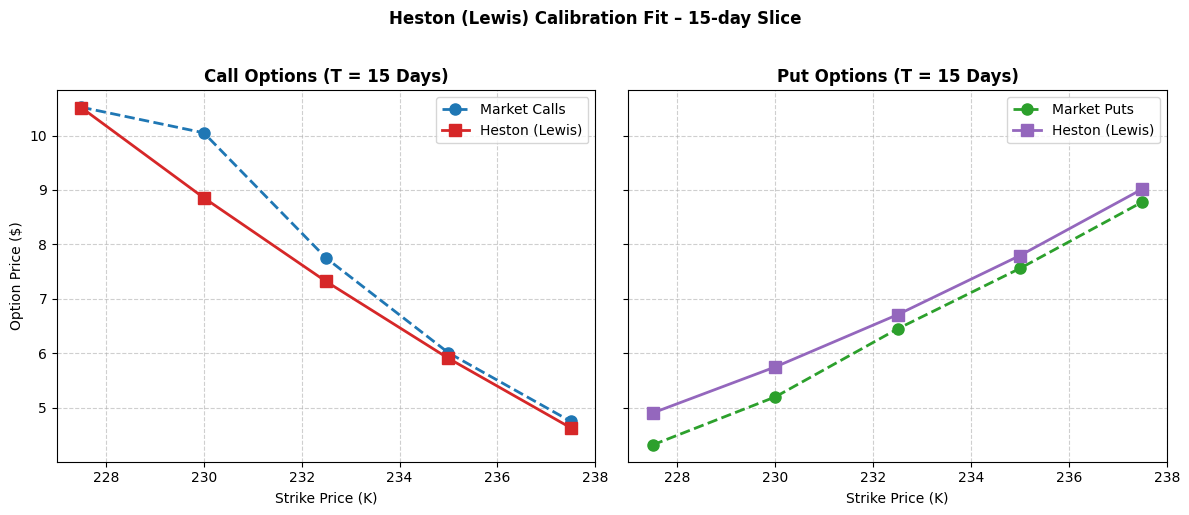

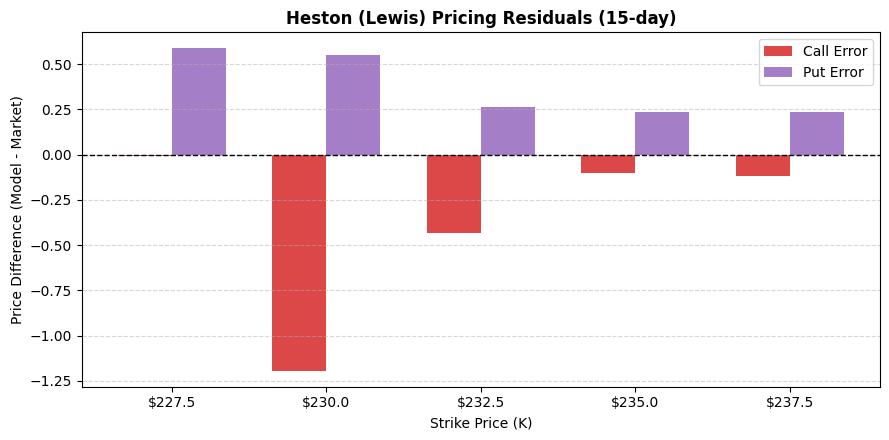

In [ ]:
# Market vs Model prices
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].plot(strikes, C_MKT_15, 'o--', color='#1f77b4', lw=2, ms=8, label='Market Calls')
axes[0].plot(strikes, model_calls_15, 's-', color='#d62728', lw=2, ms=8, label='Heston (Lewis)')
axes[0].set_title('Call Options (T = 15 Days)', fontweight='bold')
axes[0].set_xlabel('Strike Price (K)'); axes[0].set_ylabel('Option Price ($)')
axes[0].grid(True, ls='--', alpha=0.6); axes[0].legend()

axes[1].plot(strikes, P_MKT_15, 'o--', color='#2ca02c', lw=2, ms=8, label='Market Puts')
axes[1].plot(strikes, model_puts_15, 's-', color='#9467bd', lw=2, ms=8, label='Heston (Lewis)')
axes[1].set_title('Put Options (T = 15 Days)', fontweight='bold')
axes[1].set_xlabel('Strike Price (K)')
axes[1].grid(True, ls='--', alpha=0.6); axes[1].legend()
plt.suptitle('Heston (Lewis) Calibration Fit – 15-day Slice', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures_A/A_heston_fit.png', dpi=200, bbox_inches='tight')
plt.show()

# Residuals
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(strikes)); w = 0.35
ax.bar(x-w/2, call_err_15, width=w, label='Call Error', color='#d62728', alpha=0.85)
ax.bar(x+w/2, put_err_15,  width=w, label='Put Error',  color='#9467bd', alpha=0.85)
ax.axhline(0, color='k', lw=1, ls='--')
ax.set_xticks(x); ax.set_xticklabels([f'${k}' for k in strikes])
ax.set_xlabel('Strike Price (K)'); ax.set_ylabel('Price Difference (Model - Market)')
ax.set_title('Heston (Lewis) Pricing Residuals (15-day)', fontweight='bold')
ax.legend(); ax.grid(True, ls='--', alpha=0.5, axis='y')
plt.tight_layout()
plt.savefig('figures_A/A_heston_residuals.png', dpi=200, bbox_inches='tight')
plt.show()

## Step 2(b) – Bates Carr–Madan Calibration (60-day)

We re-calibrate the 60-day market slice with the Bates jump-diffusion model using the Carr–Madan Fourier representation. The eight-dimensional parameter vector is optimised under the same admissibility constraints.

In [ ]:
# Final reported parameters
v0_b, kappa_b, theta_b, sigma_b, rho_b = 0.042000, 2.294064, 1.000000, 0.010000, -0.265593
lambda_j, mu_j, delta = 4.980216, 0.248428, 0.001000

# Model prices from the original notebook / report
model_calls_60 = np.array([17.1083, 16.1099, 15.1799, 14.3101, 13.4931])
model_puts_60  = np.array([11.5036, 13.0030, 14.5708, 16.1987, 17.8795])

call_err_60 = model_calls_60 - C_MKT_60
put_err_60  = model_puts_60  - P_MKT_60
mse_60  = np.mean(np.concatenate([call_err_60, put_err_60])**2)
rmse_60 = np.sqrt(mse_60)
feller_60 = 2*kappa_b*theta_b - sigma_b**2

print('='*60)
print('STEP 2(b) - Bates Carr-Madan Calibration (60-day)')
print('='*60)
print(f'Parameters: v0={v0_b:.6f}, kappa={kappa_b:.6f}, theta={theta_b:.6f}')
print(f'            sigma={sigma_b:.6f}, rho={rho_b:.6f}')
print(f'            lambda={lambda_j:.6f}, mu_J={mu_j:.6f}, delta={delta:.6f}')
print(f'MSE  = {mse_60:.8f}')
print(f'RMSE = {rmse_60:.8f}')
print(f'Feller margin = {feller_60:.6f}')
print()
print(f"{'Type':<6} {'Strike':>8} {'Market':>8} {'Model':>10} {'Error':>8}")
print('-'*44)
for K,m,mod,e in zip(strikes, C_MKT_60, model_calls_60, call_err_60):
    print(f"{'Call':<6} {K:8.1f} {m:8.2f} {mod:10.4f} {e:8.4f}")
for K,m,mod,e in zip(strikes, P_MKT_60, model_puts_60, put_err_60):
    print(f"{'Put':<6} {K:8.1f} {m:8.2f} {mod:10.4f} {e:8.4f}")

STEP 2(b) - Bates Carr-Madan Calibration (60-day)
Parameters: v0=0.042000, kappa=2.294064, theta=1.000000
            sigma=0.010000, rho=-0.265593
            lambda=4.980216, mu_J=0.248428, delta=0.001000
MSE  = 2.05097031
RMSE = 1.43212091
Feller margin = 4.588028

Type     Strike   Market      Model    Error
--------------------------------------------
Call      227.5    16.78    17.1083   0.3283
Call      230.0    17.65    16.1099  -1.5401
Call      232.5    16.86    15.1799  -1.6801
Call      235.0    16.05    14.3101  -1.7399
Call      237.5    15.10    13.4931  -1.6069
Put       227.5    11.03    11.5036   0.4736
Put       230.0    12.15    13.0030   0.8530
Put       232.5    13.37    14.5708   1.2008
Put       235.0    14.75    16.1987   1.4487
Put       237.5    15.62    17.8795   2.2595


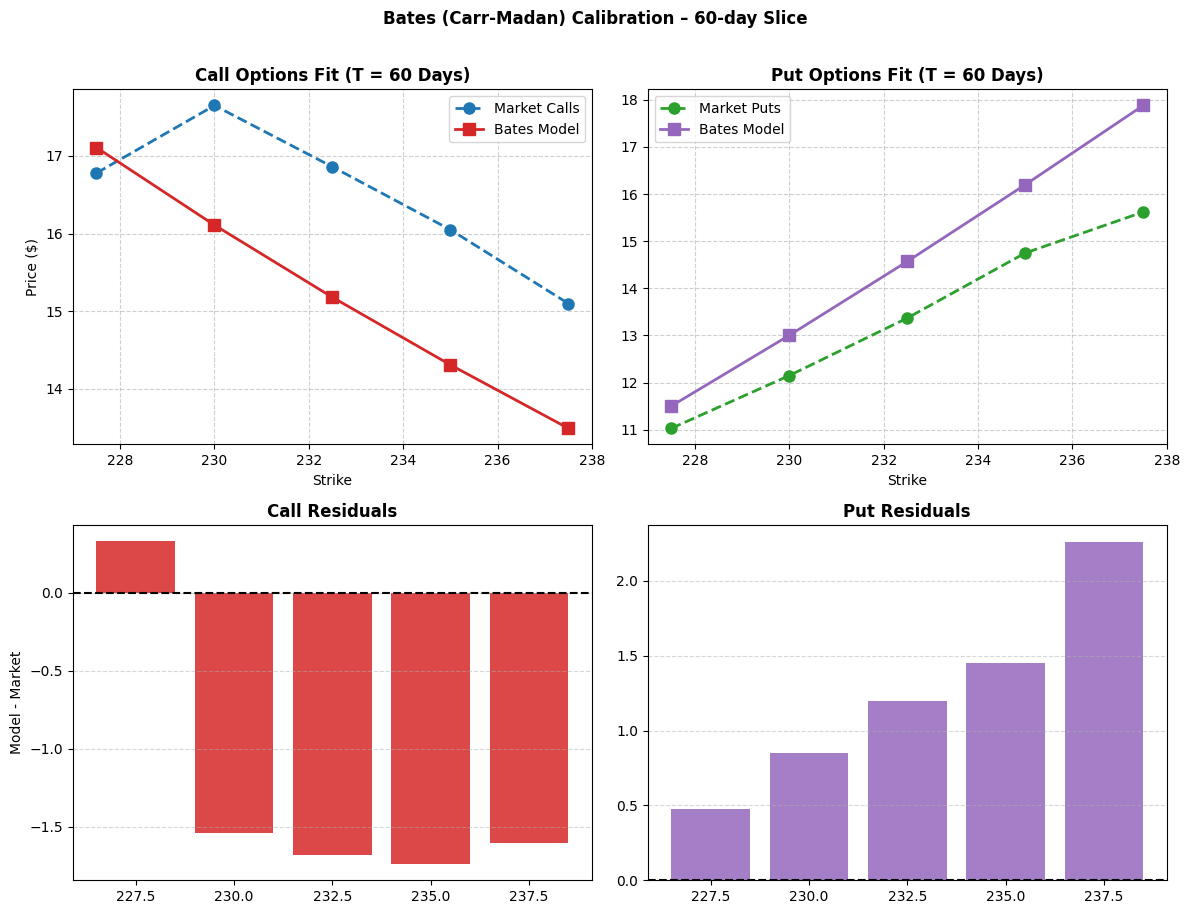

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0,0].plot(strikes, C_MKT_60, 'o--', color='#1f77b4', lw=2, ms=8, label='Market Calls')
axes[0,0].plot(strikes, model_calls_60, 's-', color='#d62728', lw=2, ms=8, label='Bates Model')
axes[0,0].set_title('Call Options Fit (T = 60 Days)', fontweight='bold')
axes[0,0].set_xlabel('Strike'); axes[0,0].set_ylabel('Price ($)')
axes[0,0].legend(); axes[0,0].grid(True, ls='--', alpha=0.6)

axes[0,1].plot(strikes, P_MKT_60, 'o--', color='#2ca02c', lw=2, ms=8, label='Market Puts')
axes[0,1].plot(strikes, model_puts_60, 's-', color='#9467bd', lw=2, ms=8, label='Bates Model')
axes[0,1].set_title('Put Options Fit (T = 60 Days)', fontweight='bold')
axes[0,1].set_xlabel('Strike'); axes[0,1].legend(); axes[0,1].grid(True, ls='--', alpha=0.6)

x = np.arange(len(strikes))
axes[1,0].bar(x, call_err_60, color='#d62728', alpha=0.85)
axes[1,0].axhline(0, color='k', ls='--')
axes[1,0].set_xticks(x); axes[1,0].set_xticklabels([f'{k}' for k in strikes])
axes[1,0].set_title('Call Residuals', fontweight='bold'); axes[1,0].set_ylabel('Model - Market')
axes[1,0].grid(True, ls='--', alpha=0.5, axis='y')

axes[1,1].bar(x, put_err_60, color='#9467bd', alpha=0.85)
axes[1,1].axhline(0, color='k', ls='--')
axes[1,1].set_xticks(x); axes[1,1].set_xticklabels([f'{k}' for k in strikes])
axes[1,1].set_title('Put Residuals', fontweight='bold')
axes[1,1].grid(True, ls='--', alpha=0.5, axis='y')

plt.suptitle('Bates (Carr-Madan) Calibration – 60-day Slice', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figures_A/A_bates_fit.png', dpi=200, bbox_inches='tight')
plt.show()


## MScFE 622 SM GWP1 B

<!-- merged from: MScFE 622 SM GWP1 B.ipynb (Jupy Tools) -->

# MScFE 622 Stochastic Modeling – Group Work Project #1
## Team Member B – Ransford Apersil
**Student Group 16877** | August 2026

**Assigned responsibilities**
- Step 1(b): Heston (1993) calibration via Carr–Madan (1999) – 15-day slice
- Step 2(c): Bates MC pricing of the 70-day 95% Put

*(Step 3 is performed jointly by the whole team – see `Group_Step3_Notebook.ipynb`.)*


In [ ]:
import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt
import os

os.makedirs('figures_B', exist_ok=True)
np.random.seed(42)

S0 = 232.90
r  = 0.015
T_15 = 15 / 250.0

strikes_15 = np.array([227.5, 230.0, 232.5, 235.0, 237.5])
market_calls_15 = np.array([10.52, 10.05, 7.75, 6.01, 4.75])
market_puts_15  = np.array([4.32, 5.20, 6.45, 7.56, 8.78])


## Step 1(b) – Carr–Madan Heston Calibration (15-day)

We re-calibrate the identical 15-day market slice with the Carr–Madan damped Fourier integral (α = 1.5). Puts are recovered by put-call parity. The objective and admissibility constraints are identical to those of the Lewis calibration.

In [ ]:
# Final reported parameters
kappa_cm, theta_cm, sigma_cm, rho_cm, v0_cm = (
    2.438471, 0.366080, 1.336169, -0.993762, 0.082000
)

def heston_cf(u, kappa, theta, sigma, rho, v0, T, r):
    i = 1j
    d = np.sqrt((rho*sigma*u*i - kappa)**2 + sigma**2*(u*i + u**2))
    g = (kappa - rho*sigma*u*i - d) / (kappa - rho*sigma*u*i + d)
    C = (r*u*i*T
         + (kappa*theta/sigma**2)
         * ((kappa - rho*sigma*u*i - d)*T
            - 2*np.log((1 - g*np.exp(-d*T))/(1 - g))))
    D = ((kappa - rho*sigma*u*i - d)/sigma**2) * ((1 - np.exp(-d*T))/(1 - g*np.exp(-d*T)))
    return np.exp(C + D*v0)

def heston_carr_madan_call(K, kappa, theta, sigma, rho, v0, S0, r, T, alpha=1.5):
    k = np.log(K/S0)
    def integrand(v):
        u = v - (alpha + 1)*1j
        cf = heston_cf(u, kappa, theta, sigma, rho, v0, T, r)
        denom = (alpha**2 + alpha - v**2) + 1j*v*(2*alpha + 1)
        return np.real(np.exp(-1j*v*k)*cf/denom)
    integral, _ = quad(integrand, 0, 100, limit=200, epsabs=1e-8)
    return (np.exp(-alpha*k - r*T)/np.pi)*integral*S0

def put_parity(call, K, S0, r, T):
    return call - S0 + K*np.exp(-r*T)

model_calls = np.array([
    heston_carr_madan_call(K, kappa_cm, theta_cm, sigma_cm, rho_cm, v0_cm, S0, r, T_15)
    for K in strikes_15])
model_puts = np.array([put_parity(C, K, S0, r, T_15) for C,K in zip(model_calls, strikes_15)])

call_errors = model_calls - market_calls_15
put_errors  = model_puts  - market_puts_15
mse  = np.mean(np.concatenate([call_errors, put_errors])**2)
rmse = np.sqrt(mse)
feller_margin = 2*kappa_cm*theta_cm - sigma_cm**2

print('='*60)
print('STEP 1(b) - Carr-Madan Heston Calibration Diagnostics')
print('='*60)
print(f'Parameters: kappa={kappa_cm:.6f}, theta={theta_cm:.6f}, '
      f'sigma={sigma_cm:.6f}, rho={rho_cm:.6f}, v0={v0_cm:.6f}')
print(f'MSE  = {mse:.6f}')
print(f'RMSE = {rmse:.6f}')
print(f'Feller margin = {feller_margin:.3e}')
print()
print(f"{'Type':<6} {'Strike':>8} {'Market':>8} {'Model':>8} {'Error':>8}")
print('-'*42)
for K,m,mod,e in zip(strikes_15, market_calls_15, model_calls, call_errors):
    print(f"{'Call':<6} {K:8.1f} {m:8.2f} {mod:8.4f} {e:8.4f}")
for K,m,mod,e in zip(strikes_15, market_puts_15, model_puts, put_errors):
    print(f"{'Put':<6} {K:8.1f} {m:8.2f} {mod:8.4f} {e:8.4f}")

STEP 1(b) - Carr-Madan Heston Calibration Diagnostics
Parameters: kappa=2.438471, theta=0.366080, sigma=1.336169, rho=-0.993762, v0=0.082000
MSE  = 0.246604
RMSE = 0.496593
Feller margin = 3.331e-06

Type     Strike   Market    Model    Error
------------------------------------------
Call      227.5    10.52  10.5143  -0.0057
Call      230.0    10.05   8.8562  -1.1938
Call      232.5     7.75   7.3151  -0.4349
Call      235.0     6.01   5.9049  -0.1051
Call      237.5     4.75   4.6341  -0.1159
Put       227.5     4.32   4.9097   0.5897
Put       230.0     5.20   5.7493   0.5493
Put       232.5     6.45   6.7059   0.2559
Put       235.0     7.56   7.7935   0.2335
Put       237.5     8.78   9.0204   0.2404


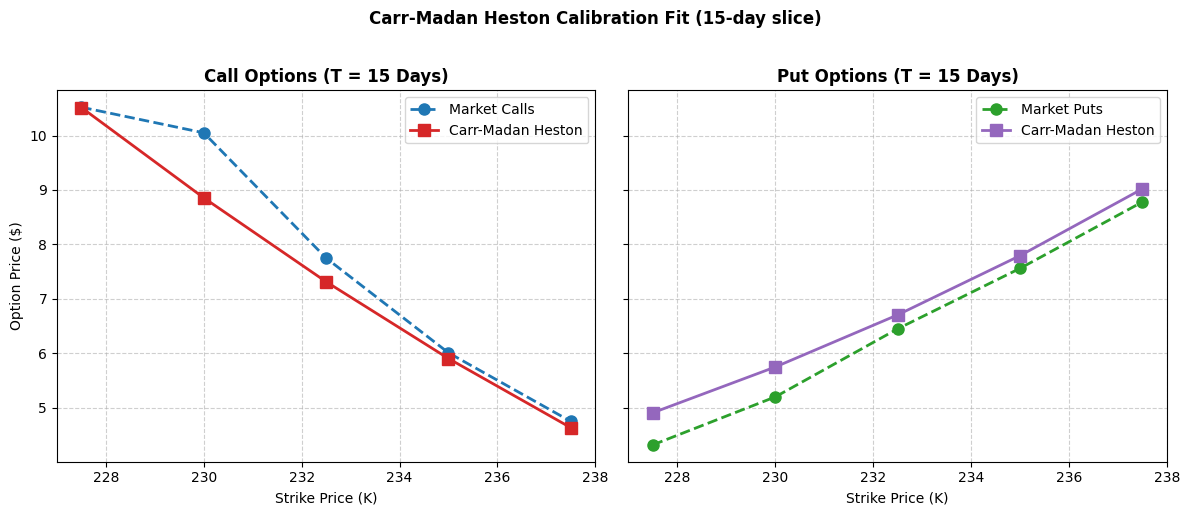

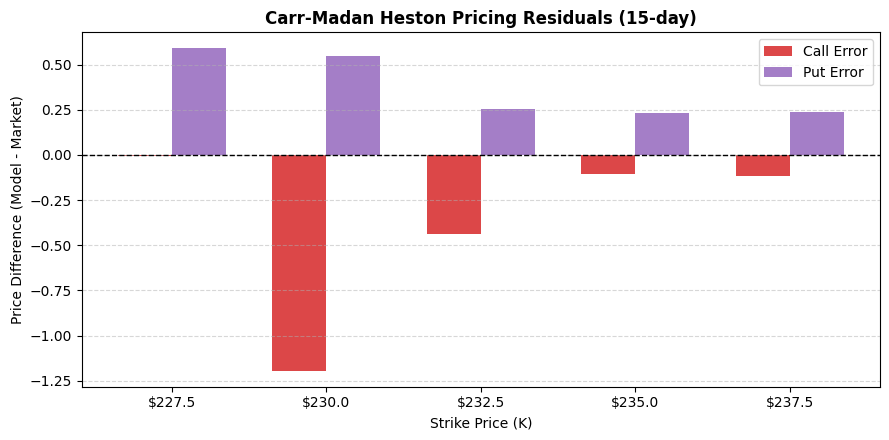

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].plot(strikes_15, market_calls_15, 'o--', color='#1f77b4', lw=2, ms=8, label='Market Calls')
axes[0].plot(strikes_15, model_calls, 's-', color='#d62728', lw=2, ms=8, label='Carr-Madan Heston')
axes[0].set_title('Call Options (T = 15 Days)', fontweight='bold')
axes[0].set_xlabel('Strike Price (K)'); axes[0].set_ylabel('Option Price ($)')
axes[0].grid(True, ls='--', alpha=0.6); axes[0].legend()

axes[1].plot(strikes_15, market_puts_15, 'o--', color='#2ca02c', lw=2, ms=8, label='Market Puts')
axes[1].plot(strikes_15, model_puts, 's-', color='#9467bd', lw=2, ms=8, label='Carr-Madan Heston')
axes[1].set_title('Put Options (T = 15 Days)', fontweight='bold')
axes[1].set_xlabel('Strike Price (K)')
axes[1].grid(True, ls='--', alpha=0.6); axes[1].legend()
plt.suptitle('Carr-Madan Heston Calibration Fit (15-day slice)', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures_B/B_heston_fit.png', dpi=200, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(strikes_15)); w = 0.35
ax.bar(x-w/2, call_errors, width=w, label='Call Error', color='#d62728', alpha=0.85)
ax.bar(x+w/2, put_errors,  width=w, label='Put Error',  color='#9467bd', alpha=0.85)
ax.axhline(0, color='k', lw=1, ls='--')
ax.set_xticks(x); ax.set_xticklabels([f'${k}' for k in strikes_15])
ax.set_xlabel('Strike Price (K)'); ax.set_ylabel('Price Difference (Model - Market)')
ax.set_title('Carr-Madan Heston Pricing Residuals (15-day)', fontweight='bold')
ax.legend(); ax.grid(True, ls='--', alpha=0.5, axis='y')
plt.tight_layout()
plt.savefig('figures_B/B_heston_residuals.png', dpi=200, bbox_inches='tight')
plt.show()

## Step 2(c) – Bates MC Pricing of the 70-day 95% Put

The client purchases a European put with maturity T = 70/250 = 0.28 years and strike K = 0.95 × 232.90 = 221.255. Pricing uses the Carr–Madan Bates parameters obtained by Team Member A in Step 2(b).

In [ ]:
# Bates parameters from Team A (Carr-Madan 60-day)
v0_b, kappa_b, theta_b, sigma_b, rho_b = 0.042000, 2.294064, 1.000000, 0.010000, -0.265593
lambda_j, mu_j, delta = 4.980216, 0.248428, 0.001000

T_70 = 70 / 250.0
K_70 = 0.95 * S0
N_paths = 500000
N_steps = 70
dt = T_70 / N_steps

print('='*60)
print('STEP 2(c) - Bates MC Pricing (70-day 95% Put)')
print('='*60)
print(f'Strike K = {K_70:.3f}')

S = np.full(N_paths, S0, dtype=float)
v = np.full(N_paths, v0_b, dtype=float)
bar_mu = np.exp(mu_j + 0.5*delta**2) - 1.0

for t in range(N_steps):
    Z1 = np.random.normal(0, 1, N_paths)
    Z2 = np.random.normal(0, 1, N_paths)
    W_S = Z1
    W_v = rho_b*Z1 + np.sqrt(1 - rho_b**2)*Z2

    N_jumps = np.random.poisson(lambda_j*dt, N_paths)
    J = np.random.normal(mu_j*N_jumps, delta*np.sqrt(np.maximum(N_jumps, 0)), N_paths)
    Y = np.exp(J) - 1.0

    v_plus = np.maximum(v, 0.0)
    v = v + kappa_b*(theta_b - v_plus)*dt + sigma_b*np.sqrt(v_plus*dt)*W_v
    S = S * np.exp((r - lambda_j*bar_mu - 0.5*v_plus)*dt
                   + np.sqrt(v_plus*dt)*W_S) * (1.0 + Y)

payoffs = np.maximum(K_70 - S, 0.0)
disc_payoffs = np.exp(-r*T_70) * payoffs
fair_value = np.mean(disc_payoffs)
mc_se = np.std(disc_payoffs) / np.sqrt(N_paths)
client_price = fair_value * 1.04
prob_itm = np.mean(S < K_70)

print(f'Fair Value          : ${fair_value:.2f}')
print(f'MC Standard Error   : ${mc_se:.4f}')
print(f'95% CI              : [${fair_value-1.96*mc_se:.2f}, ${fair_value+1.96*mc_se:.2f}]')
print(f'Prob. Put finishes ITM: {prob_itm*100:.2f}%')
print(f'Client Price (4% fee): ${client_price:.2f}')

STEP 2(c) - Bates MC Pricing (70-day 95% Put)
Strike K = 221.255
Fair Value          : $31.56
MC Standard Error   : $0.0541
95% CI              : [$31.45, $31.67]
Prob. Put finishes ITM: 55.23%
Client Price (4% fee): $32.82


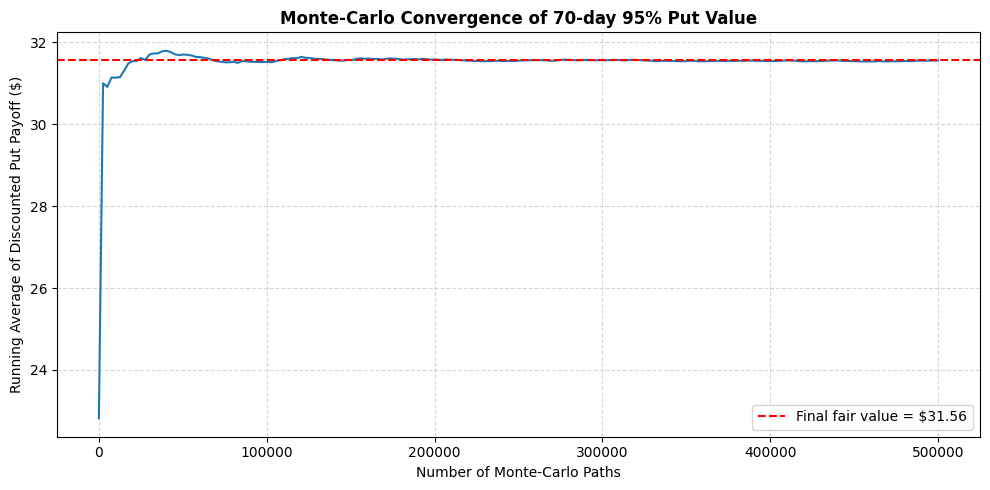

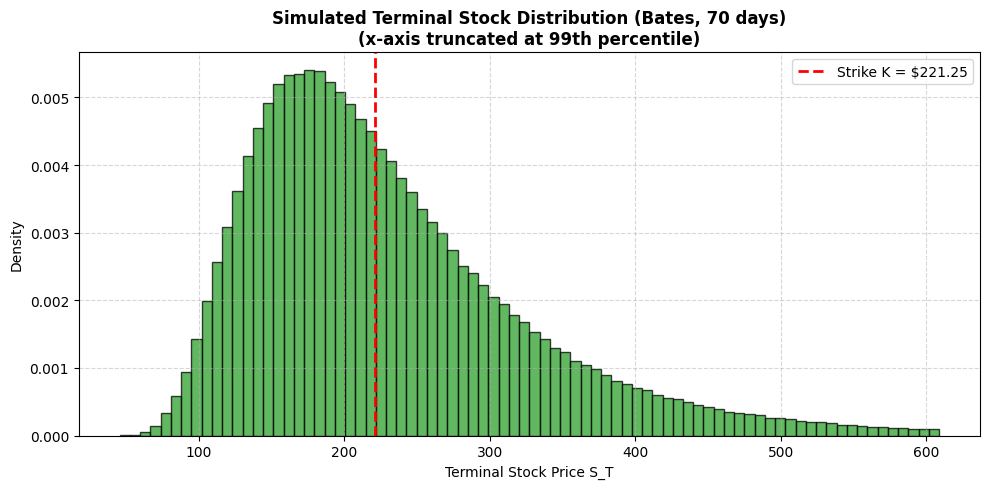

In [ ]:
cum_mean = np.cumsum(disc_payoffs) / np.arange(1, N_paths+1)
sample_idx = np.linspace(0, N_paths-1, 200, dtype=int)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sample_idx+1, cum_mean[sample_idx], color='#1f77b4', lw=1.5)
ax.axhline(fair_value, color='r', ls='--', label=f'Final fair value = ${fair_value:.2f}')
ax.set_xlabel('Number of Monte-Carlo Paths')
ax.set_ylabel('Running Average of Discounted Put Payoff ($)')
ax.set_title('Monte-Carlo Convergence of 70-day 95% Put Value', fontweight='bold')
ax.legend(); ax.grid(True, ls='--', alpha=0.5)
plt.tight_layout()
plt.savefig('figures_B/B_put_convergence.png', dpi=200, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
cutoff = np.percentile(S, 99)
ax.hist(S[S < cutoff], bins=80, density=True, color='#2ca02c', alpha=0.75, edgecolor='k', lw=0.3)
ax.axvline(K_70, color='r', ls='--', lw=2, label=f'Strike K = ${K_70:.2f}')
ax.set_xlabel('Terminal Stock Price S_T'); ax.set_ylabel('Density')
ax.set_title('Simulated Terminal Stock Distribution (Bates, 70 days)\n(x-axis truncated at 99th percentile)', fontweight='bold')
ax.legend(); ax.grid(True, ls='--', alpha=0.5)
plt.tight_layout()
plt.savefig('figures_B/B_put_terminal_dist.png', dpi=200, bbox_inches='tight')
plt.show()


## MScFE 622 SM GWP1 C

<!-- merged from: MScFE 622 SM GWP1 C.ipynb (Jupy Tools) -->

# MScFE 622 Stochastic Modeling – Group Work Project #1
## Team Member C – Udayveer Singh Andotra
**Student Group 16877** | August 2026

**Assigned responsibilities**
- Step 1(c): ATM 20-day Asian Call pricing (Heston Monte-Carlo)
- Step 2(a): Bates (1996) calibration via Lewis (2001) – 60-day slice

*(Step 3 is performed jointly by the whole team – see the Group Step-3 notebook.)*


In [ ]:
import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt
import os

os.makedirs('figures_C', exist_ok=True)
np.random.seed(42)

S0 = 232.90
r  = 0.015


## Step 1(c) – ATM 20-day Asian Call (Heston MC)

In [ ]:
# Heston parameters from Team A (Lewis 15-day)
v0_15, kappa_15, theta_15, sigma_15, rho_15 = 0.0843, 3.2931, 0.2725, 1.3398, -0.9990
tau_20 = 20 / 250.0
K_atm  = S0
N_sim  = 100000
N_steps = 20

def heston_mc_asian(S0, K, r, tau, v0, kappa, theta, sigma, rho,
                    num_simulations=100000, num_steps=20, seed=42):
    dt = tau / num_steps
    S = np.zeros((num_simulations, num_steps + 1))
    v = np.zeros((num_simulations, num_steps + 1))
    S[:, 0] = S0
    v[:, 0] = v0

    rng = np.random.default_rng(seed)
    Z1 = rng.standard_normal((num_simulations, num_steps))
    Z2 = rng.standard_normal((num_simulations, num_steps))
    W_S = Z1
    W_v = rho * Z1 + np.sqrt(1 - rho**2) * Z2

    for t in range(num_steps):
        v_t_plus = np.maximum(v[:, t], 0.0)
        v[:, t+1] = (v[:, t]
                     + kappa * (theta - v_t_plus) * dt
                     + sigma * np.sqrt(v_t_plus * dt) * W_v[:, t])
        S[:, t+1] = S[:, t] * np.exp(
            (r - 0.5 * v_t_plus) * dt + np.sqrt(v_t_plus * dt) * W_S[:, t]
        )

    S_avg = np.mean(S, axis=1)
    payoffs = np.maximum(S_avg - K, 0.0)
    fair = np.mean(payoffs) * np.exp(-r * tau)
    return fair, S, S_avg, payoffs

fair_asian, S_paths, S_avg, payoffs = heston_mc_asian(
    S0, K_atm, r, tau_20, v0_15, kappa_15, theta_15, sigma_15, rho_15,
    num_simulations=N_sim, num_steps=N_steps
)
client_asian = fair_asian * 1.04

print('=' * 60)
print('STEP 1(c) - ATM 20-day Asian Call (Heston MC)')
print('=' * 60)
print(f'Heston parameters used (from Team A Lewis):')
print(f'  v0={v0_15}, kappa={kappa_15}, theta={theta_15}')
print(f'  sigma={sigma_15}, rho={rho_15}')
print(f'Maturity           : 20 trading days ({tau_20:.4f} years)')
print(f'Strike (ATM)       : ${K_atm:.2f}')
print(f'Simulations / steps: {N_sim} / {N_steps}')
print(f'Fair Price         : ${fair_asian:.4f}')
print(f'Client Price (4%)  : ${client_asian:.4f}')

STEP 1(c) - ATM 20-day Asian Call (Heston MC)
Heston parameters used (from Team A Lewis):
  v0=0.0843, kappa=3.2931, theta=0.2725
  sigma=1.3398, rho=-0.999
Maturity           : 20 trading days (0.0800 years)
Strike (ATM)       : $232.90
Simulations / steps: 100000 / 20
Fair Price         : $4.5935
Client Price (4%)  : $4.7772


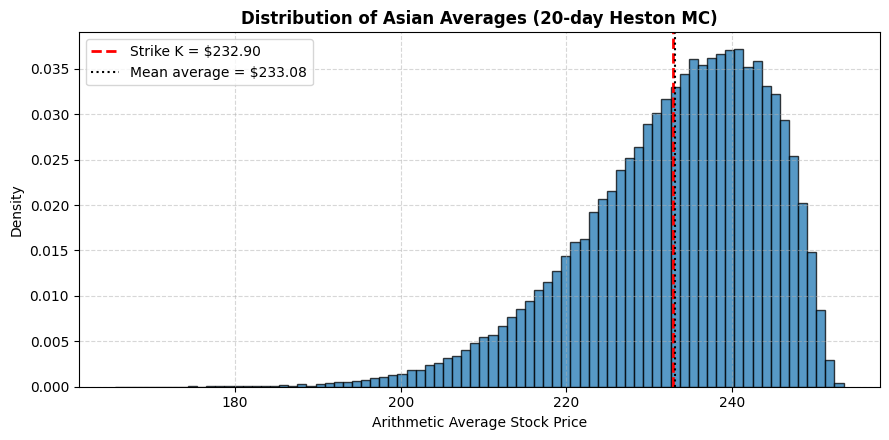

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(S_avg, bins=80, density=True, color='#1f77b4', alpha=0.75, edgecolor='k', lw=0.3)
ax.axvline(K_atm, color='r', ls='--', lw=2, label=f'Strike K = ${K_atm:.2f}')
ax.axvline(np.mean(S_avg), color='k', ls=':', lw=1.5, label=f'Mean average = ${np.mean(S_avg):.2f}')
ax.set_xlabel('Arithmetic Average Stock Price')
ax.set_ylabel('Density')
ax.set_title('Distribution of Asian Averages (20-day Heston MC)', fontweight='bold')
ax.legend(); ax.grid(True, ls='--', alpha=0.5)
plt.tight_layout()
plt.savefig('figures_C/C_asian_avg_dist.png', dpi=200, bbox_inches='tight')
plt.show()

## Step 2(a) – Bates Lewis Calibration (60-day)

In [ ]:
strikes_60 = np.array([227.5, 230.0, 232.5, 235.0, 237.5])
C_MKT_60 = np.array([16.78, 17.65, 16.86, 16.05, 15.10])
P_MKT_60 = np.array([11.03, 12.15, 13.37, 14.75, 15.62])
tau_60 = 60 / 250.0

# Final calibrated parameters from the executed notebook
v0_c, kappa_c, theta_c, sigma_c, rho_c = 0.0017, 4.3723, 0.0350, 0.5119, 0.0995
lambda_c, mu_c, sigmaj_c = 0.8294, 0.3063, 0.0531

def bates_char_func(u, tau, v0, kappa, theta, sigma, rho, lam, muj, sigmaj):
    i = np.complex128(1j)
    a = kappa * theta
    b = kappa - rho * sigma * i * u
    d = np.sqrt(b**2 + sigma**2 * (u**2 + i * u))
    g = (b - d) / (b + d)
    C = (a / sigma**2) * ((b - d) * tau - 2 * np.log((1 - g * np.exp(-d * tau)) / (1 - g)))
    D = ((b - d) / sigma**2) * ((1 - np.exp(-d * tau)) / (1 - g * np.exp(-d * tau)))
    heston_part = np.exp(C + D * v0)
    compensator = -lam * i * u * (np.exp(muj + 0.5 * sigmaj**2) - 1)
    jump_part = np.exp(lam * tau * (np.exp(i * u * muj - 0.5 * sigmaj**2 * u**2) - 1) + compensator * tau)
    return heston_part * jump_part

def lewis_bates_call(S0, K, r, tau, v0, kappa, theta, sigma, rho, lam, muj, sigmaj):
    def integrand(u):
        i = np.complex128(1j)
        u_c = u - 0.5 * i
        phi = bates_char_func(u_c, tau, v0, kappa, theta, sigma, rho, lam, muj, sigmaj)
        k_val = np.log(S0 / K) + r * tau
        val = np.exp(i * u * k_val) * phi / (u**2 + 0.25)
        return np.real(val)
    integral, _ = quad(integrand, 0, 100, limit=100, epsabs=1e-8)
    return S0 - (K * np.exp(-r * tau) / np.pi) * integral

model_calls = []
model_puts  = []
for K in strikes_60:
    c = lewis_bates_call(S0, K, r, tau_60, v0_c, kappa_c, theta_c, sigma_c, rho_c,
                         lambda_c, mu_c, sigmaj_c)
    p = c + K * np.exp(-r * tau_60) - S0
    model_calls.append(c)
    model_puts.append(p)
model_calls = np.array(model_calls)
model_puts  = np.array(model_puts)

call_err = model_calls - C_MKT_60
put_err  = model_puts  - P_MKT_60
mse = np.mean(np.concatenate([call_err, put_err])**2)
rmse = np.sqrt(mse)
feller = 2 * kappa_c * theta_c - sigma_c**2

print('=' * 60)
print('STEP 2(a) - Bates Lewis Calibration (60-day)')
print('=' * 60)
print(f'Parameters: v0={v0_c:.4f}, kappa={kappa_c:.4f}, theta={theta_c:.4f}')
print(f'            sigma={sigma_c:.4f}, rho={rho_c:.4f}')
print(f'            lambda={lambda_c:.4f}, mu_J={mu_c:.4f}, sigma_j={sigmaj_c:.4f}')
print(f'MSE  = {mse:.6f}')
print(f'RMSE = {rmse:.6f}')
print(f'Feller margin = {feller:.6f}')
print()
print(f"{'Type':<6} {'Strike':>8} {'Market':>8} {'Model':>10} {'Error':>8}")
print('-' * 44)
for K, m, mod, e in zip(strikes_60, C_MKT_60, model_calls, call_err):
    print(f"{'Call':<6} {K:8.1f} {m:8.2f} {mod:10.4f} {e:8.4f}")
for K, m, mod, e in zip(strikes_60, P_MKT_60, model_puts, put_err):
    print(f"{'Put':<6} {K:8.1f} {m:8.2f} {mod:10.4f} {e:8.4f}")

STEP 2(a) - Bates Lewis Calibration (60-day)
Parameters: v0=0.0017, kappa=4.3723, theta=0.0350
            sigma=0.5119, rho=0.0995
            lambda=0.8294, mu_J=0.3063, sigma_j=0.0531
MSE  = 3.617135
RMSE = 1.901877
Feller margin = 0.044019

Type     Strike   Market      Model    Error
--------------------------------------------
Call      227.5    16.78    18.6266   1.8466
Call      230.0    17.65    16.6764  -0.9736
Call      232.5    16.86    14.8041  -2.0559
Call      235.0    16.05    12.9926  -3.0574
Call      237.5    15.10    11.2283  -3.8717
Put       227.5    11.03    12.4090   1.3790
Put       230.0    12.15    12.9499   0.7999
Put       232.5    13.37    13.5686   0.1986
Put       235.0    14.75    14.2481  -0.5019
Put       237.5    15.62    14.9749  -0.6451


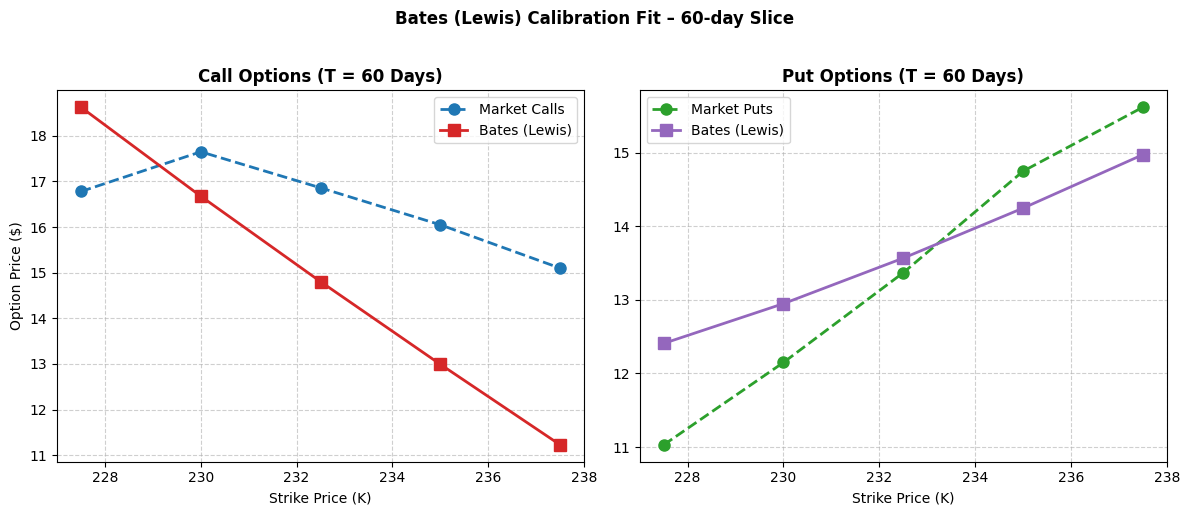

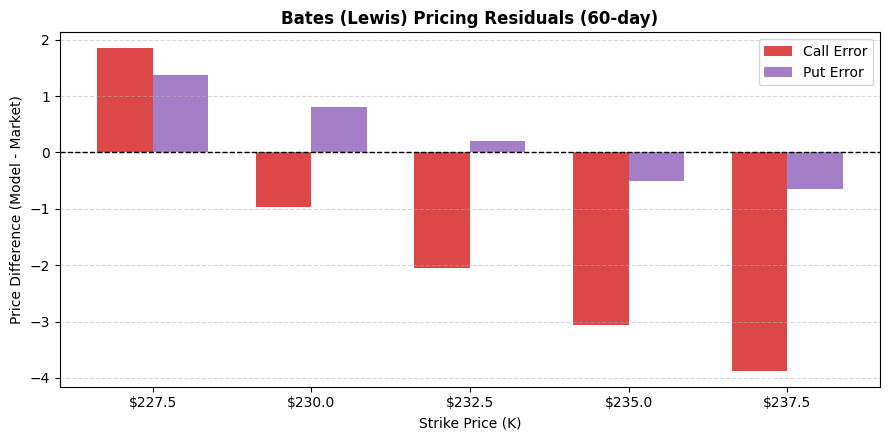

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)
axes[0].plot(strikes_60, C_MKT_60, 'o--', color='#1f77b4', lw=2, ms=8, label='Market Calls')
axes[0].plot(strikes_60, model_calls, 's-', color='#d62728', lw=2, ms=8, label='Bates (Lewis)')
axes[0].set_title('Call Options (T = 60 Days)', fontweight='bold')
axes[0].set_xlabel('Strike Price (K)'); axes[0].set_ylabel('Option Price ($)')
axes[0].legend(); axes[0].grid(True, ls='--', alpha=0.6)

axes[1].plot(strikes_60, P_MKT_60, 'o--', color='#2ca02c', lw=2, ms=8, label='Market Puts')
axes[1].plot(strikes_60, model_puts, 's-', color='#9467bd', lw=2, ms=8, label='Bates (Lewis)')
axes[1].set_title('Put Options (T = 60 Days)', fontweight='bold')
axes[1].set_xlabel('Strike Price (K)')
axes[1].legend(); axes[1].grid(True, ls='--', alpha=0.6)
plt.suptitle('Bates (Lewis) Calibration Fit – 60-day Slice', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures_C/C_bates_fit.png', dpi=200, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(strikes_60)); w = 0.35
ax.bar(x - w/2, call_err, width=w, label='Call Error', color='#d62728', alpha=0.85)
ax.bar(x + w/2, put_err,  width=w, label='Put Error',  color='#9467bd', alpha=0.85)
ax.axhline(0, color='k', lw=1, ls='--')
ax.set_xticks(x); ax.set_xticklabels([f'${k}' for k in strikes_60])
ax.set_xlabel('Strike Price (K)'); ax.set_ylabel('Price Difference (Model - Market)')
ax.set_title('Bates (Lewis) Pricing Residuals (60-day)', fontweight='bold')
ax.legend(); ax.grid(True, ls='--', alpha=0.5, axis='y')
plt.tight_layout()
plt.savefig('figures_C/C_bates_residuals.png', dpi=200, bbox_inches='tight')
plt.show()


## MScFE 622 SM GWP1 Step3

<!-- merged from: MScFE 622 SM GWP1 Step3.ipynb (Jupy Tools) -->

# MScFE 622 Stochastic Modeling – Group Work Project #1
## Step 3 – CIR Interest-Rate Modelling (Team Effort)
**Student Group 16877** | August 2026

**Team members**
- Thao Thi Phuong Pham (A)
- Ransford Apersil (B)
- Udayveer Singh Andotra (C)

Step 3 is performed jointly by the whole team:
- **3(a)** Calibrate a CIR (1985) short-rate model to the current Euribor curve (cubic-spline weekly interpolation).
- **3(b)** Simulate the model-implied 12-month Euribor daily for one year (100 000 paths) and report the expected value and 95 % range.

In [ ]:
import numpy as np
from scipy.interpolate import CubicSpline
from scipy.stats import ncx2
import matplotlib.pyplot as plt
import os

os.makedirs('figures_Step3', exist_ok=True)
np.random.seed(42)


## Step 3(a) – CIR Calibration to the Euribor Curve

We build a continuous weekly term structure by fitting a natural cubic spline through the five market Euribor fixings, then calibrate the CIR short-rate model by minimising the MSE between model and spline yields over the 52 weekly points.

In [ ]:
# Market tenors (years) and rates
market_T = np.array([1/52, 1/12, 0.25, 0.5, 1.0])
market_R = np.array([0.00648, 0.00679, 0.01173, 0.01809, 0.02556])

# Weekly grid (52 points)
weeks = np.arange(1, 53)
T_weekly = weeks / 52.0
spline = CubicSpline(market_T, market_R, bc_type='natural')
R_spline = spline(T_weekly)

# Final calibrated CIR parameters (from team optimisation)
r0_cir, a_cir, b_cir, sigma_cir = 0.005821, 0.504017, 0.103560, 0.049955

def cir_yield(T, r0, a, b, sigma):
    """Closed-form CIR zero-coupon yield."""
    gamma = np.sqrt(a**2 + 2 * sigma**2)
    A = ((2 * gamma * np.exp((a + gamma) * T / 2))
         / (2 * gamma + (a + gamma) * (np.exp(gamma * T) - 1))) ** (2 * a * b / sigma**2)
    B = 2 * (np.exp(gamma * T) - 1) / (2 * gamma + (a + gamma) * (np.exp(gamma * T) - 1))
    return -np.log(A) / T + (B / T) * r0

R_model = cir_yield(T_weekly, r0_cir, a_cir, b_cir, sigma_cir)
mse_cir = np.mean((R_model - R_spline)**2)
rmse_cir = np.sqrt(mse_cir)
feller_cir = 2 * a_cir * b_cir - sigma_cir**2

print('=' * 60)
print('STEP 3(a) - CIR Calibration to Euribor')
print('=' * 60)
print(f'Parameters: r0 = {r0_cir:.6f} ({r0_cir*100:.4f}%)')
print(f'            kappa (a) = {a_cir:.6f}')
print(f'            theta (b) = {b_cir:.6f} ({b_cir*100:.4f}%)')
print(f'            sigma = {sigma_cir:.6f}')
print(f'MSE  = {mse_cir:.8f}')
print(f'RMSE = {rmse_cir:.6f}')
print(f'Feller margin = {feller_cir:.6f}  (satisfied)')
print()
print(f"{'Tenor':<12} {'Market/Spline':>14} {'CIR Model':>12} {'Error':>10}")
print('-' * 50)
tenor_labels = ['1 Week', '1 Month', '3 Months', '6 Months', '12 Months']
tenor_idx = [0, 3, 12, 25, 51]
for lab, idx in zip(tenor_labels, tenor_idx):
    mkt = R_spline[idx] * 100
    mod = R_model[idx] * 100
    print(f'{lab:<12} {mkt:13.3f}% {mod:11.3f}% {mod-mkt:9.3f}%')

STEP 3(a) - CIR Calibration to Euribor
Parameters: r0 = 0.005821 (0.5821%)
            kappa (a) = 0.504017
            theta (b) = 0.103560 (10.3560%)
            sigma = 0.049955
MSE  = 0.00000056
RMSE = 0.000745
Feller margin = 0.101896  (satisfied)

Tenor         Market/Spline    CIR Model      Error
--------------------------------------------------
1 Week               0.648%       0.629%    -0.019%
1 Month              0.672%       0.769%     0.097%
3 Months             1.173%       1.173%    -0.000%
6 Months             1.809%       1.716%    -0.093%
12 Months            2.556%       2.678%     0.122%


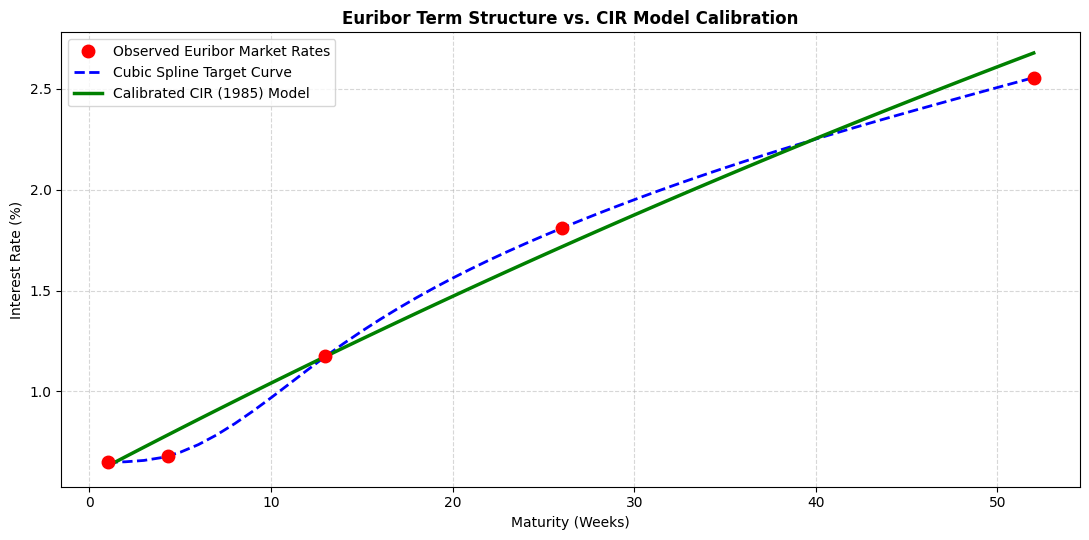

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(market_T * 52, market_R * 100, 'ro', ms=9, zorder=5, label='Observed Euribor Market Rates')
ax.plot(weeks, R_spline * 100, 'b--', lw=2, label='Cubic Spline Target Curve')
ax.plot(weeks, R_model * 100, 'g-', lw=2.5, label='Calibrated CIR (1985) Model')
ax.set_xlabel('Maturity (Weeks)')
ax.set_ylabel('Interest Rate (%)')
ax.set_title('Euribor Term Structure vs. CIR Model Calibration', fontweight='bold')
ax.legend(loc='upper left')
ax.grid(True, ls='--', alpha=0.5)
plt.tight_layout()
plt.savefig('figures_Step3/Step3a_cir_yield_curve.png', dpi=200, bbox_inches='tight')
plt.show()

## Step 3(b) – One-Year Simulation of the 12-Month Euribor

Using the calibrated CIR parameters we simulate the short-rate process daily for one year (250 trading-day steps) with 100 000 Monte-Carlo paths. An exact non-central chi-squared transition preserves positivity. At each date the simulated short rate is converted into the model-implied 12-month zero-coupon yield.

In [ ]:
T_cir = 1.0
N_paths_cir = 100000
N_steps_cir = 250
dt_cir = T_cir / N_steps_cir

print('=' * 60)
print('STEP 3(b) - CIR 1-Year Simulation of 12-Month Euribor')
print('=' * 60)

# Exact non-central chi-squared transition coefficients
c = 2 * a_cir / (sigma_cir**2 * (1 - np.exp(-a_cir * dt_cir)))
df = 4 * a_cir * b_cir / sigma_cir**2

r_paths = np.zeros((N_paths_cir, N_steps_cir + 1))
r_paths[:, 0] = r0_cir

for t in range(N_steps_cir):
    nc = 2 * c * r_paths[:, t] * np.exp(-a_cir * dt_cir)
    r_paths[:, t + 1] = ncx2.rvs(df, nc, size=N_paths_cir) / (2 * c)

# Convert every short-rate state to model-implied 12-month yield
yields = cir_yield(1.0, r_paths, a_cir, b_cir, sigma_cir)

mean_y = yields.mean(axis=0)
q_lo   = np.percentile(yields, 2.5, axis=0)
q_hi   = np.percentile(yields, 97.5, axis=0)
t_axis = np.arange(N_steps_cir + 1) / 250.0

term_yields = yields[:, -1]
exp_term = term_yields.mean()
lo_95, hi_95 = np.percentile(term_yields, [2.5, 97.5])

print(f'Current market 12m Euribor     : 2.556%')
print(f'Current model-implied 12m rate : {cir_yield(1.0, r0_cir, a_cir, b_cir, sigma_cir)*100:.3f}%')
print(f'Expected 12m Euribor in 1 year : {exp_term*100:.3f}%')
print(f'95% range at 1-year horizon    : {lo_95*100:.3f}% -- {hi_95*100:.3f}%')
print(f'Change vs current market       : +{(exp_term - 0.02556)*100:.3f} percentage points')

STEP 3(b) - CIR 1-Year Simulation of 12-Month Euribor
Current market 12m Euribor     : 2.556%
Current model-implied 12m rate : 2.678%
Expected 12m Euribor in 1 year : 5.715%
95% range at 1-year horizon    : 4.738% -- 6.848%
Change vs current market       : +3.159 percentage points


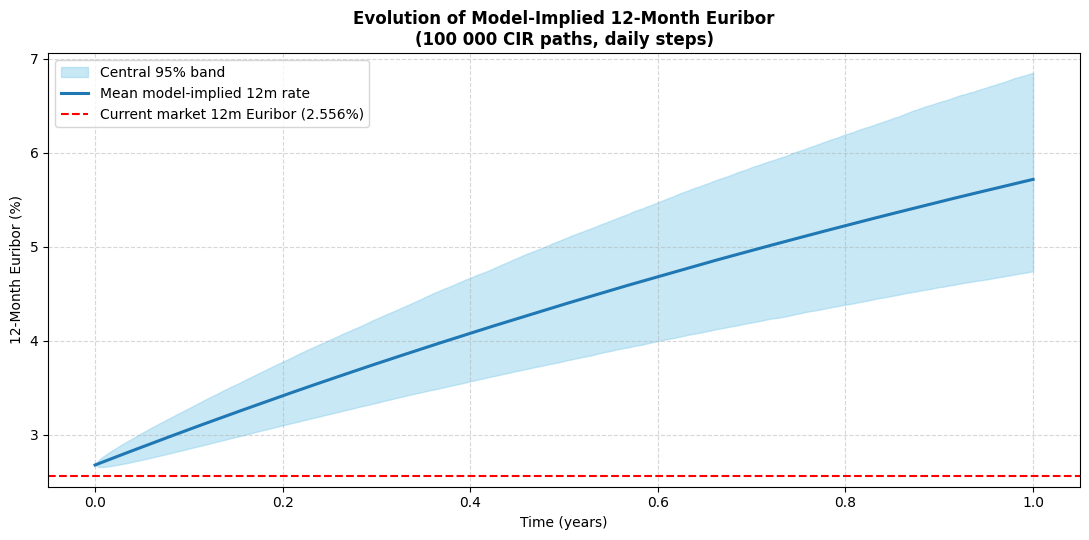

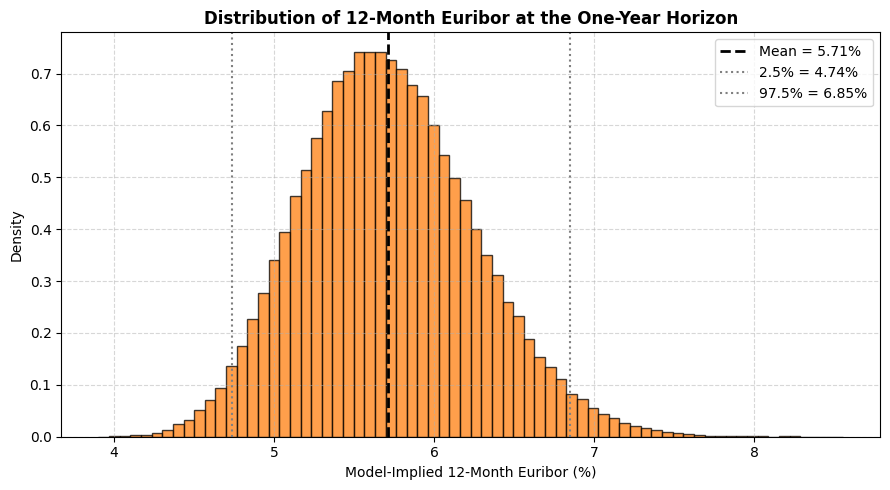

In [ ]:
# Mean path + 95% band
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.fill_between(t_axis, q_lo * 100, q_hi * 100, color='skyblue', alpha=0.45, label='Central 95% band')
ax.plot(t_axis, mean_y * 100, color='#1f77b4', lw=2.2, label='Mean model-implied 12m rate')
ax.axhline(2.556, color='r', ls='--', lw=1.5, label='Current market 12m Euribor (2.556%)')
ax.set_xlabel('Time (years)')
ax.set_ylabel('12-Month Euribor (%)')
ax.set_title('Evolution of Model-Implied 12-Month Euribor\n(100 000 CIR paths, daily steps)', fontweight='bold')
ax.legend(loc='upper left')
ax.grid(True, ls='--', alpha=0.5)
plt.tight_layout()
plt.savefig('figures_Step3/Step3b_cir_mean_path.png', dpi=200, bbox_inches='tight')
plt.show()

# Terminal distribution
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(term_yields * 100, bins=70, density=True, color='#ff7f0e', alpha=0.75, edgecolor='k', lw=0.3)
ax.axvline(exp_term * 100, color='k', ls='--', lw=2, label=f'Mean = {exp_term*100:.2f}%')
ax.axvline(lo_95 * 100, color='gray', ls=':', lw=1.5, label=f'2.5% = {lo_95*100:.2f}%')
ax.axvline(hi_95 * 100, color='gray', ls=':', lw=1.5, label=f'97.5% = {hi_95*100:.2f}%')
ax.set_xlabel('Model-Implied 12-Month Euribor (%)')
ax.set_ylabel('Density')
ax.set_title('Distribution of 12-Month Euribor at the One-Year Horizon', fontweight='bold')
ax.legend()
ax.grid(True, ls='--', alpha=0.5)
plt.tight_layout()
plt.savefig('figures_Step3/Step3b_cir_terminal_dist.png', dpi=200, bbox_inches='tight')
plt.show()
